# Mini-Project 5 — Taxi Route Revenue, Pricing & Fleet Planner

**Scenario.** A taxi (matatu) association runs 14-seater vehicles on three routes out of Kampala. It wants to forecast demand, understand fares and decide how many vehicles to deploy.

**Data provenance.** The Kampala–Ntinda counts are from the original question; the Entebbe and Mukono counts are **illustrative**, as stated in the assignment. The demand and supply equations, fares, vehicle capacity, trips per day and 15 % buffer are assignment assumptions. The 60-day series in the extension is **simulated** with a fixed seed (pattern stated in Section 6).

All reusable logic is in `src/taxi_routes.py` (tested in `tests/test_taxi_routes.py`). This `Forecaster` hierarchy is deliberately separate from Mini-Project 1's: those models forecast annual levels years ahead, these make one-day-ahead forecasts of daily counts.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import matplotlib.pyplot as plt

from src.taxi_routes import (
    Route, equilibrium, excess_demand,
    MovingAverageForecaster, SESForecaster, LinearTrendForecaster, SeasonalNaiveForecaster,
    backtest, tune_alpha, vehicles_needed, simulate_weekly, WEEKDAYS,
)

SEED = 2026
START_DAY = 4          # backtest targets days 4-10
np.set_printoptions(precision=2, suppress=True)

## 1. The `Route` class: revenue and descriptive statistics (Task 1)

In [2]:
routes = [
    Route("Kampala-Ntinda",  [35, 40, 42, 50, 55, 60, 48, 52, 47, 45], 2000, "Original question"),
    Route("Kampala-Entebbe", [60, 58, 65, 70, 72, 80, 75, 68, 66, 64], 5000, "Illustrative"),
    Route("Kampala-Mukono",  [45, 47, 50, 49, 55, 62, 58, 53, 51, 50], 3000, "Illustrative"),
]
print(f"{'Route':<16} {'Fare':>7} {'Mean pax':>9} {'Variance':>9} {'SD':>6} {'CV':>6} {'Total revenue (UGX)':>20} {'Share':>6}")
grand = sum(r.total_revenue() for r in routes)
for r in routes:
    s = r.stats()
    print(f"{r.name:<16} {r.fare_ugx:7,.0f} {s['mean']:9.1f} {s['variance']:9.2f} {s['stdev']:6.2f} {s['stdev'] / s['mean']:6.3f} "
          f"{r.total_revenue():20,.0f} {r.total_revenue() / grand:6.0%}")
print(f"\nHand check, Ntinda total: {int(sum(routes[0].passengers))} passengers x 2,000 = {int(sum(routes[0].passengers)) * 2000:,} UGX")

Route               Fare  Mean pax  Variance     SD     CV  Total revenue (UGX)  Share
Kampala-Ntinda     2,000      47.4     54.27   7.37  0.155              948,000    16%
Kampala-Entebbe    5,000      67.8     45.07   6.71  0.099            3,390,000    57%
Kampala-Mukono     3,000      52.0     26.44   5.14  0.099            1,560,000    26%

Hand check, Ntinda total: 474 passengers x 2,000 = 948,000 UGX


Entebbe carries the most passengers *and* has the highest fare, so it earns more than half of the association's revenue over the ten days. Ntinda has the lowest fare and the most relative variability (highest CV): its counts rise steadily to a peak on day 6 and then fall back.

## 2. Supply–demand equilibrium on the Ntinda route (Task 2)

Demand $Q_d = 120 - 0.02P$ and supply $Q_s = 10 + 0.03P$, with $P$ the fare in UGX and $Q$ passengers per trip-hour. At equilibrium both equal the same $Q$, so

$$\begin{pmatrix}1 & 0.02\\ 1 & -0.03\end{pmatrix}\begin{pmatrix}Q\\ P\end{pmatrix} = \begin{pmatrix}120\\ 10\end{pmatrix}.$$

By hand: $120 - 0.02P = 10 + 0.03P \Rightarrow 110 = 0.05P \Rightarrow P^* = 2{,}200$, and $Q^* = 120 - 0.02 \times 2{,}200 = 76$.

In [3]:
p_star, q_star = equilibrium()
A = np.array([[1, 0.02], [1, -0.03]])
print(f"Equilibrium fare P* = UGX {p_star:,.2f}, quantity Q* = {q_star:.2f} passengers per trip-hour")
print(f"det(A) = {np.linalg.det(A):.4f}, condition number = {np.linalg.cond(A):.1f}")
P = 2000
print(f"At the current fare UGX {P:,}: demand {120 - 0.02 * P:.0f}, supply {10 + 0.03 * P:.0f}, "
      f"excess demand {excess_demand(P):+.0f} passengers per trip-hour")

Equilibrium fare P* = UGX 2,200.00, quantity Q* = 76.00 passengers per trip-hour
det(A) = -0.0500, condition number = 40.0
At the current fare UGX 2,000: demand 80, supply 70, excess demand +10 passengers per trip-hour


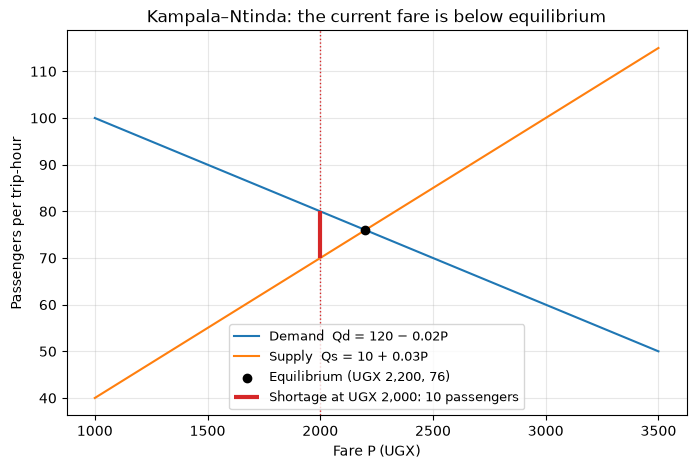

In [4]:
prices = np.linspace(1000, 3500, 100)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(prices, 120 - 0.02 * prices, color="tab:blue", label="Demand  Qd = 120 − 0.02P")
ax.plot(prices, 10 + 0.03 * prices, color="tab:orange", label="Supply  Qs = 10 + 0.03P")
ax.scatter([p_star], [q_star], color="black", zorder=3, label=f"Equilibrium (UGX {p_star:,.0f}, {q_star:.0f})")
ax.vlines(P, 10 + 0.03 * P, 120 - 0.02 * P, color="tab:red", linewidth=3, label=f"Shortage at UGX {P:,}: {excess_demand(P):.0f} passengers")
ax.axvline(P, color="tab:red", linestyle=":", linewidth=1)
ax.set_xlabel("Fare P (UGX)"); ax.set_ylabel("Passengers per trip-hour")
ax.set_title("Kampala–Ntinda: the current fare is below equilibrium")
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.show()

**Interpretation.** The current UGX 2,000 fare is **UGX 200 below** the equilibrium of UGX 2,200. At UGX 2,000, 80 passengers want to travel per trip-hour but operators supply only 70 places, a **shortage of 10 passengers per trip-hour**: queues at the stage, full vehicles and touts with pricing power. Raising the fare to about UGX 2,200 would clear the market in this model, by discouraging some riders and drawing in more supply. Two cautions: the equations are assumptions, not estimates from Ntinda data, and their $Q$ is passengers **per trip-hour**, a different unit from the daily counts, so 76 should not be compared directly with the route's 35–60 passengers per day. The condition number of 40 is larger than in Project 2 only because the two unknowns have very different scales (passengers versus thousands of shillings), not because the system is fragile.

## 3. Forecasters (Task 3)

All four classes inherit from the abstract `Forecaster` base, which validates the history once and exposes `fit(history)` and `predict()` (next day):

* **MA(3)** — mean of the last three days, the original method.
* **SES(α)** — simple exponential smoothing $s_t = \alpha x_t + (1-\alpha)s_{t-1}$, level initialised at day 1 (stated assumption); forecast = final level. $\alpha = 1$ is the naive forecast "tomorrow = today".
* **Linear trend** — least-squares line through all past days, extended one day.
* **Seasonal naive** (extension) — the value from the same weekday last week.

In [5]:
x = routes[0].passengers
print("Ntinda, forecasts for day 11 from days 1-10:")
for model in (MovingAverageForecaster(3), SESForecaster(0.5), SESForecaster(1.0), LinearTrendForecaster()):
    print(f"  {model.name:<16} {model.fit(x).predict():6.2f}")
print(f"Hand check MA(3): (52 + 47 + 45) / 3 = {(52 + 47 + 45) / 3:.2f}")

Ntinda, forecasts for day 11 from days 1-10:
  MA(3)             48.00
  SES(alpha=0.50)   47.19
  SES(alpha=1.00)   45.00
  LinearTrend       53.67
Hand check MA(3): (52 + 47 + 45) / 3 = 48.00


## 4. Walk-forward backtesting and tuning α (Task 4)

For each target day $t = 4, \dots, 10$ a **fresh** model is fitted on days $1, \dots, t-1$ only and forecasts day $t$ — exactly what an operator could have done in real time. That gives seven one-step-ahead forecasts per model and route, scored by MAE (passengers). α is chosen by grid search over 0.01, 0.02, …, 1.00 on the same backtest; ties go to the smaller α.

In [6]:
results, best_alpha, mae_curves = {}, {}, {}
print(f"{'Route':<16} {'best alpha':>10} {'MA(3)':>7} {'SES(best)':>10} {'Linear':>7} {'SES(0.3)':>9}   selected")
for r in routes:
    alpha, curve = tune_alpha(r.passengers, start_day=START_DAY)
    best_alpha[r.name], mae_curves[r.name] = alpha, curve
    res = {
        "MA(3)": backtest(r.passengers, lambda: MovingAverageForecaster(3), START_DAY),
        "SES": backtest(r.passengers, lambda a=alpha: SESForecaster(a), START_DAY),
        "Linear": backtest(r.passengers, LinearTrendForecaster, START_DAY),
        "SES(0.3)": backtest(r.passengers, lambda: SESForecaster(0.3), START_DAY),
    }
    results[r.name] = res
    best = min(("MA(3)", "SES", "Linear"), key=lambda k: res[k]["mae"])
    res["best"] = best
    print(f"{r.name:<16} {alpha:10.2f} {res['MA(3)']['mae']:7.2f} {res['SES']['mae']:10.2f} {res['Linear']['mae']:7.2f} "
          f"{res['SES(0.3)']['mae']:9.2f}   {best}")

Route            best alpha   MA(3)  SES(best)  Linear  SES(0.3)   selected
Kampala-Ntinda         0.98    7.52       5.86    7.87      7.35   SES
Kampala-Entebbe        1.00    7.19       4.43    7.71      7.03   SES
Kampala-Mukono         1.00    5.33       3.71    6.39      4.95   SES


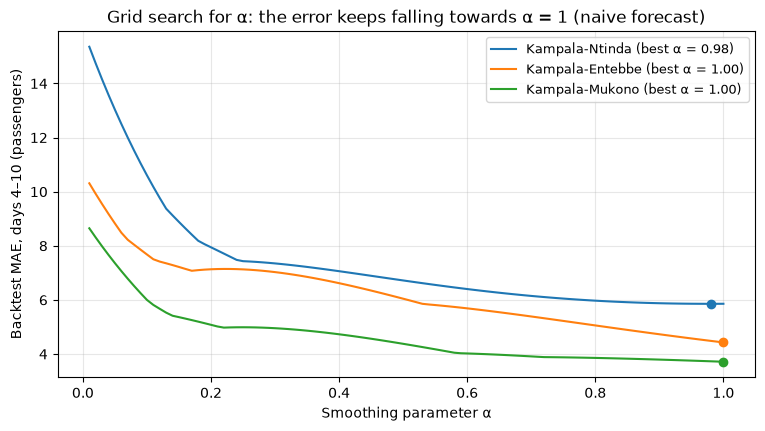

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = {"Kampala-Ntinda": "tab:blue", "Kampala-Entebbe": "tab:orange", "Kampala-Mukono": "tab:green"}
for name, curve in mae_curves.items():
    alphas = np.array(list(curve)); maes = np.array(list(curve.values()))
    ax.plot(alphas, maes, color=colors[name], label=f"{name} (best α = {best_alpha[name]:.2f})")
    ax.scatter([best_alpha[name]], [curve[best_alpha[name]]], color=colors[name], zorder=3)
ax.set_xlabel("Smoothing parameter α"); ax.set_ylabel("Backtest MAE, days 4–10 (passengers)")
ax.set_title("Grid search for α: the error keeps falling towards α = 1 (naive forecast)")
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.show()

**Interpretation.** On every route the backtest error falls, almost steadily, as α rises, and the best α is **0.98 for Ntinda and 1.00 for Entebbe and Mukono**. At α = 1 exponential smoothing *is* the naive forecast, so the tuning is telling us something important: over these ten days, the best predictor of tomorrow is simply today. The series move in runs (up to day 6, then down), and any averaging — MA(3), a small α, or a straight line through all past days — lags behind those turns. The linear trend does worst because the series rise and then fall, which a single straight line cannot follow.

**Caution — selection bias.** α was chosen on the same seven days it is scored on, so the SES errors are optimistic; with ten observations there is no separate data to check them. A fixed, untuned α = 0.3 (last column of the table) performs only modestly better than MA(3). The ranking rests on seven errors per route and could easily change with more data.

## 5. Day-11 revenue forecast and fleet planning (Tasks 5 and 6)

Each route's best model (lowest backtest MAE) is refitted on all ten days to forecast day 11. Revenue = forecast passengers × fare. Fleet: each vehicle makes 8 one-way trips at 14 passengers, a capacity of **112 passengers per day**; we add a 15 % buffer and **round up** (a fraction of a vehicle cannot be deployed, and rounding down would leave passengers behind), with at least one vehicle per route.

$$\text{vehicles} = \max\left(1, \left\lceil \frac{1.15 \times \text{forecast}}{8 \times 14} \right\rceil\right)$$

In [8]:
MAKE = {"MA(3)": lambda name: MovingAverageForecaster(3),
        "SES": lambda name: SESForecaster(best_alpha[name]),
        "Linear": lambda name: LinearTrendForecaster()}
day11 = {}
print(f"{'Route':<16} {'Model':<16} {'Day-11 pax':>10} {'Revenue (UGX)':>14} {'x1.15':>7} {'/112':>6} {'Vehicles':>9} {'Pax for 2nd vehicle':>20}")
for r in routes:
    best = results[r.name]["best"]
    model = MAKE[best](r.name).fit(r.passengers)
    pax = model.predict()
    day11[r.name] = (model, pax)
    threshold = int(np.floor(112 / 1.15)) + 1
    print(f"{r.name:<16} {model.name:<16} {pax:10.1f} {pax * r.fare_ugx:14,.0f} {pax * 1.15:7.1f} {pax * 1.15 / 112:6.2f} "
          f"{vehicles_needed(pax):9d} {threshold:>20}")
total = sum(pax * r.fare_ugx for r, (_, pax) in zip(routes, day11.values()))
print(f"\nForecast day-11 revenue, all routes: UGX {total:,.0f}")

Route            Model            Day-11 pax  Revenue (UGX)   x1.15   /112  Vehicles  Pax for 2nd vehicle
Kampala-Ntinda   SES(alpha=0.98)        45.0         90,084    51.8   0.46         1                   98
Kampala-Entebbe  SES(alpha=1.00)        64.0        320,000    73.6   0.66         1                   98
Kampala-Mukono   SES(alpha=1.00)        50.0        150,000    57.5   0.51         1                   98

Forecast day-11 revenue, all routes: UGX 560,084


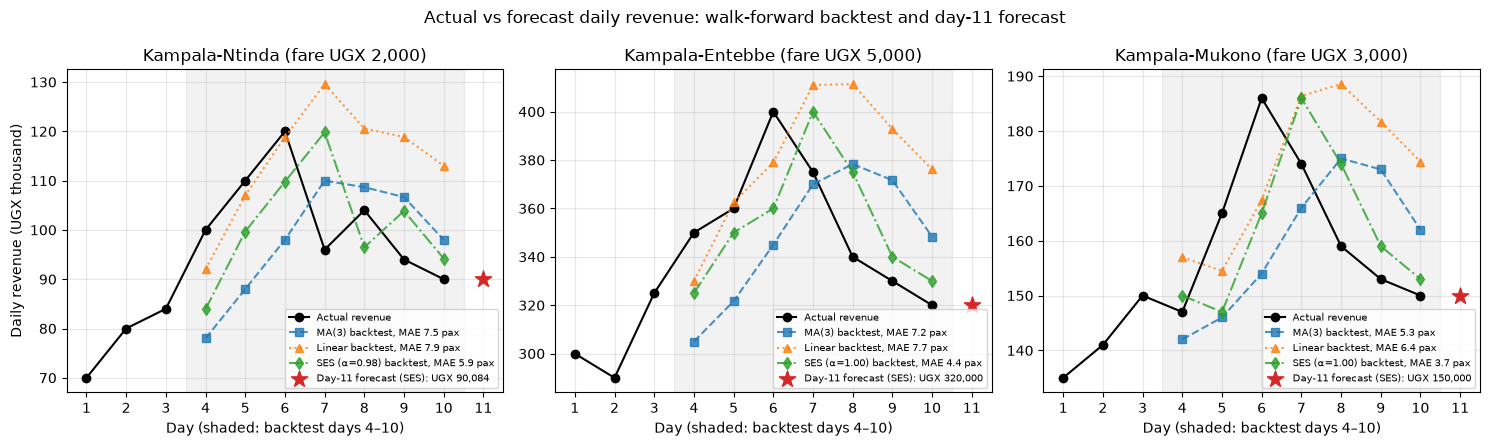

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True)
for ax, r in zip(axes, routes):
    res = results[r.name]
    best = res["best"]
    ax.plot(np.arange(1, 11), r.daily_revenue() / 1000, "ko-", label="Actual revenue")
    for key, style in (("MA(3)", "s--"), ("Linear", "^:"), ("SES", "d-.")):
        b = res[key]
        label = f"{key if key != 'SES' else f'SES (α={best_alpha[r.name]:.2f})'} backtest, MAE {b['mae']:.1f} pax"
        ax.plot(b["days"], b["forecasts"] * r.fare_ugx / 1000, style, alpha=0.8, label=label)
    model, pax = day11[r.name]
    ax.scatter([11], [pax * r.fare_ugx / 1000], s=150, marker="*", color="tab:red", zorder=4,
               label=f"Day-11 forecast ({best}): UGX {pax * r.fare_ugx:,.0f}")
    ax.axvspan(START_DAY - 0.5, 10.5, color="grey", alpha=0.1)
    ax.set_title(f"{r.name} (fare UGX {r.fare_ugx:,.0f})")
    ax.set_xlabel("Day (shaded: backtest days 4–10)")
    ax.set_xticks(range(1, 12)); ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc="lower right")
axes[0].set_ylabel("Daily revenue (UGX thousand)")
fig.suptitle("Actual vs forecast daily revenue: walk-forward backtest and day-11 forecast")
fig.tight_layout()
plt.show()

**Interpretation.** The best models forecast about 45, 64 and 50 passengers on day 11, worth roughly UGX 90,000, 320,000 and 150,000. Even with the 15 % buffer, each forecast fills only 46–66 % of **one** vehicle's daily capacity of 112, so the rule gives **one vehicle per route**. A second vehicle would only be justified above 98 passengers a day. That answer is arithmetically correct but operationally suspicious: a single matatu doing eight trips is a very thin service for routes such as Kampala–Entebbe. The most likely explanation is that the daily counts are a sample — for example one stage, one direction or one observation period — rather than the route's full demand. Before acting, the association should check what the counts measure; if they are a sample, the same calculation should be rerun on scaled-up totals. The one-vehicle answer also ignores peak hours: demand is concentrated in the morning and evening, and capacity per trip, not per day, is what limits service then.

## 6. Extension: a 60-day weekly pattern

**Simulation (stated assumptions).** For each route, day 1 is a Monday and the base level is the route's 10-day mean. Fridays are 30 % busier and Sundays 30 % quieter; every day gets independent multiplicative noise $1 + N(0, 0.08)$, rounded to whole passengers. Each route uses its own seed (2026, 2027, 2028) so the routes do not share the same noise.

**Fair comparison.** Seasonal naive needs one full week of history, so both models are scored on exactly the same days (8–60, 53 forecasts each), with the same walk-forward procedure as above.

In [10]:
sim, ext = {}, {}
print(f"{'Route':<16} {'MA(3) MAE':>10} {'Seasonal-naive MAE':>19} {'Reduction':>10} {'SN better on':>13}")
for i, r in enumerate(routes):
    series = simulate_weekly(r.passengers.mean(), days=60, seed=SEED + i)
    sim[r.name] = series
    ma = backtest(series, lambda: MovingAverageForecaster(3), start_day=8)
    sn = backtest(series, lambda: SeasonalNaiveForecaster(7), start_day=8)
    ext[r.name] = (ma, sn)
    wins = np.mean(np.abs(sn["errors"]) < np.abs(ma["errors"]))
    print(f"{r.name:<16} {ma['mae']:10.2f} {sn['mae']:19.2f} {1 - sn['mae'] / ma['mae']:10.0%} {wins:12.0%} of days")

print("\nMAE by weekday of the target day (Ntinda):")
ma, sn = ext["Kampala-Ntinda"]
wd = np.array([WEEKDAYS[(d - 1) % 7] for d in ma["days"]])
for day in WEEKDAYS:
    m = wd == day
    print(f"  {day}: MA(3) {np.mean(np.abs(ma['errors'][m])):5.1f}   seasonal naive {np.mean(np.abs(sn['errors'][m])):5.1f}")

Route             MA(3) MAE  Seasonal-naive MAE  Reduction  SN better on
Kampala-Ntinda         8.77                3.87        56%          74% of days
Kampala-Entebbe       10.57                6.25        41%          70% of days
Kampala-Mukono         8.21                5.81        29%          60% of days

MAE by weekday of the target day (Ntinda):
  Mon: MA(3)   3.6   seasonal naive   7.0
  Tue: MA(3)   5.4   seasonal naive   3.0
  Wed: MA(3)   4.2   seasonal naive   2.8
  Thu: MA(3)   4.0   seasonal naive   2.2
  Fri: MA(3)  18.4   seasonal naive   4.3
  Sat: MA(3)   8.1   seasonal naive   3.7
  Sun: MA(3)  20.1   seasonal naive   4.1


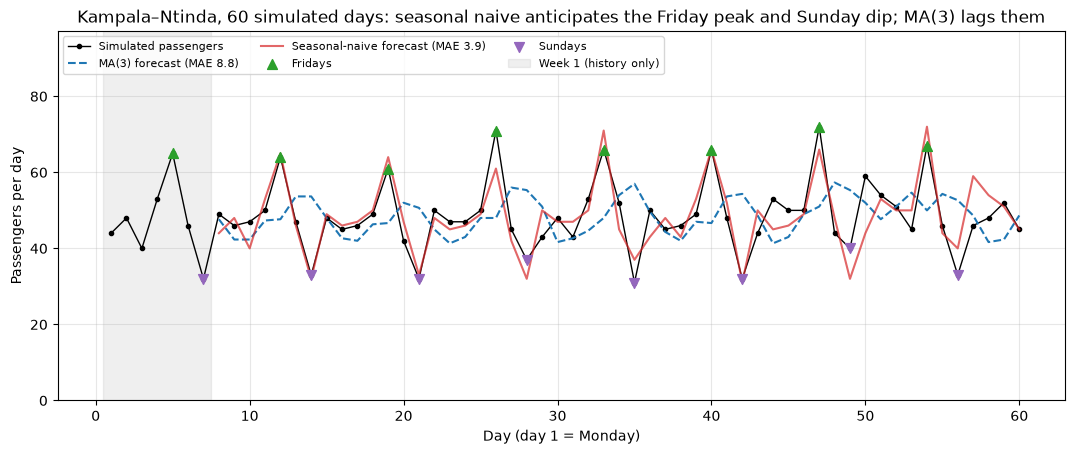

In [11]:
fig, ax = plt.subplots(figsize=(13, 4.8))
name = "Kampala-Ntinda"
series, (ma, sn) = sim[name], ext[name]
days = np.arange(1, 61)
ax.plot(days, series, "k.-", linewidth=1, label="Simulated passengers")
ax.plot(ma["days"], ma["forecasts"], "--", color="tab:blue", label=f"MA(3) forecast (MAE {ma['mae']:.1f})")
ax.plot(sn["days"], sn["forecasts"], "-", color="tab:red", alpha=0.7, label=f"Seasonal-naive forecast (MAE {sn['mae']:.1f})")
fri = days[[WEEKDAYS[(d - 1) % 7] == "Fri" for d in days]]
sun = days[[WEEKDAYS[(d - 1) % 7] == "Sun" for d in days]]
ax.scatter(fri, series[fri - 1], marker="^", color="tab:green", s=50, zorder=3, label="Fridays")
ax.scatter(sun, series[sun - 1], marker="v", color="tab:purple", s=50, zorder=3, label="Sundays")
ax.axvspan(0.5, 7.5, color="grey", alpha=0.12, label="Week 1 (history only)")
ax.set_xlabel("Day (day 1 = Monday)"); ax.set_ylabel("Passengers per day")
ax.set_title("Kampala–Ntinda, 60 simulated days: seasonal naive anticipates the Friday peak and Sunday dip; MA(3) lags them")
ax.legend(fontsize=8, ncol=3, loc="upper left"); ax.grid(alpha=0.3)
ax.set_ylim(0, series.max() * 1.35)
plt.show()

**Interpretation.** On all three routes seasonal naive beats MA(3), cutting the forecast error by roughly 30–56 % and winning on 60–74 % of days. The weekday breakdown shows why: MA(3) is badly wrong exactly on the days that matter — it under-forecasts every Friday, over-forecasts every Sunday, and carries the Friday surge into Saturday's forecast. Seasonal naive copies last week's same day, so it anticipates the peak and the dip. The one day where MA(3) wins is **Monday**: its window (Friday + Saturday + Sunday) averages a +30 % and a −30 % day, which cancel, so it is accidentally well calibrated, while seasonal naive copies one noisy Monday. Copying a single day is noisier than averaging three, which is the price seasonal naive pays for capturing the pattern.

**Limitations.** This result is built into the simulation: we generated a strong, stable weekly pattern, so a model that repeats the weekly pattern is bound to win. Real demand also has holidays, school terms, paydays and fuel-price changes, which a pure seasonal-naive model ignores. A natural next step is a model that combines both ideas — for example exponential smoothing applied to each weekday's level.

## 7. Findings & Limitations

*Word count: approximately 255.*

**Findings.** Kampala–Entebbe is the association's most important route, earning more than half of revenue because it combines the most passengers with the highest fare. On Ntinda the UGX 2,000 fare sits UGX 200 below the equilibrium of UGX 2,200, leaving a shortage of about 10 passengers per trip-hour; under these demand and supply assumptions a modest fare rise, or more vehicles at the current fare, would reduce queuing. In walk-forward backtesting, simple exponential smoothing with α close to 1 — effectively "tomorrow equals today" — beat the 3-day moving average and the linear trend on every route, because the short series move in runs that averaging methods follow too slowly. The day-11 forecasts of about 45, 64 and 50 passengers need only one vehicle per route, even with a 15 % buffer. In the 60-day extension, a seasonal-naive forecaster cut the moving average's error by roughly 30–56 % by anticipating the Friday peak and Sunday dip.

**Limitations.** Ten days is far too short for reliable forecasting: each model is judged on seven errors, and α was tuned on the same days used to score it, so the SES advantage is optimistic. Two of the three routes' data are illustrative. The equilibrium equations are assumed rather than estimated, and their trip-hour units do not match the daily counts. The one-vehicle answer is probably an artefact of the counts measuring only part of each route's demand, and daily capacity ignores rush-hour peaks. The extension's success is partly guaranteed by the way the data were simulated.